In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, roc_auc_score, brier_score_loss,
                             PrecisionRecallDisplay)

df = pd.read_parquet("features.parquet")
print("Rows and columns:", df.shape)
print("Unique patients:", df["subject_id"].nunique())

Rows and columns: (725334, 101)
Unique patients: 53984


In [10]:
df = pd.read_parquet("features.parquet")
df.head()


,subject_id,hadm_id,snapshot_time,y_24h,y_48h,age,gender_male,admission_type,admission_location,careunit,...,lactate_count24h,magnesium_count24h,pco2_count24h,ph_count24h,platelets_count24h,po2_count24h,potassium_count24h,sodium_count24h,troponin_t_count24h,wbc_count24h
0,10000032,22841357,2180-06-27 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
1,10000032,25742920,2180-08-06 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
2,10000032,25742920,2180-08-07 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0,1.0
3,10000690,23280645,2150-09-17 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10000690,23280645,2150-09-18 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,1.0


In [30]:
print(df.columns.tolist())
print(df.dtypes.value_counts)

['subject_id', 'hadm_id', 'snapshot_time', 'y_24h', 'y_48h', 'age', 'gender_male', 'admission_type', 'admission_location', 'careunit', 'hours_since_admit', 'days_since_prev_disch', 'n_prior_adm_total', 'n_prior_adm_365d', 'prior_icu_any', 'prev_los_days', 'hx_chf', 'hx_copd', 'hx_ckd', 'hx_diabetes', 'hx_cancer', 'hx_liver', 'hx_sepsis', 'omr_bmi', 'omr_dbp', 'omr_sbp', 'omr_weight_lbs', 'curr_service', 'rx_new_24h', 'rx_iv_new_24h', 'rx_antibiotic_24h', 'rx_vasopressor_24h', 'rx_diuretic_24h', 'rx_opioid_24h', 'rx_insulin_24h', 'rx_anticoagulant_24h', 'rx_acei_24h', 'rx_antibiotic_iv_24h', 'albumin_last', 'albumin_delta', 'anion_gap_last', 'anion_gap_delta', 'bicarbonate_last', 'bicarbonate_delta', 'bilirubin_last', 'bilirubin_delta', 'bun_last', 'bun_delta', 'calcium_last', 'calcium_delta', 'chloride_last', 'chloride_delta', 'creatinine_last', 'creatinine_delta', 'glucose_last', 'glucose_delta', 'hemoglobin_last', 'hemoglobin_delta', 'inr_last', 'inr_delta', 'lactate_last', 'lactate_

In [32]:
print(pd.crosstab(df["y_24h"], df["y_48h"]))
assert (df["y_24h"] <= df["y_48h"]).all()

assert not df.duplicated(["subject_id", "hadm_id", "snapshot_time"]).any()
assert df["snapshot_time"].dt.strftime("%H:%M:%S").eq("08:00:00").all()

y_48h       0     1
y_24h              
0      714093  4724
1           0  6517


## Split patients into training, validation, and test sets



In [33]:

patient_labels = df.groupby("subject_id")[["y_24h", "y_48h"]].max()
patient_ids = patient_labels.index

groups = 2 * patient_labels["y_24h"] + patient_labels["y_48h"]
dev_ids, test_ids = train_test_split(patient_ids, test_size=0.20,
                                     stratify=groups, random_state=7275)
train_ids, val_ids = train_test_split(dev_ids, test_size=0.25,
                                      stratify=groups.loc[dev_ids], random_state=7275)


train = df["subject_id"].isin(train_ids)
val = df["subject_id"].isin(val_ids)
test = df["subject_id"].isin(test_ids)
assert (train.astype(int) + val.astype(int) + test.astype(int)).eq(1).all()
print("Patients in train, validation, reserved test:", len(train_ids), len(val_ids), len(test_ids))
print("Snapshots in train, validation, reserved test:", train.sum(), val.sum(), test.sum())

Patients in train, validation, reserved test: 32390 10797 10797
Snapshots in train, validation, reserved test: 436844 146091 142399


## Select Features (X) and Target Variables (y)


In [34]:

X = df.drop(columns=["subject_id", "hadm_id", "snapshot_time", "y_24h", "y_48h"])
X_train, X_val = X.loc[train], X.loc[val]


y_24h = df["y_24h"]
y_48h = df["y_48h"]
print("Training X:", X_train.shape)
print("Validation X:", X_val.shape)
print("Training y for 24 hours:", y_24h.loc[train].shape)
print("Training y for 48 hours:", y_48h.loc[train].shape)

Training X: (436844, 96)
Validation X: (146091, 96)
Training y for 24 hours: (436844,)
Training y for 48 hours: (436844,)


## Prepare the Features for Model Training


In [35]:

numbers = X_train.select_dtypes(include="number").columns
categories = X_train.columns.difference(numbers, sort=False)
print("Categorical columns:", categories.tolist())


numeric_steps = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
category_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                               OneHotEncoder(handle_unknown="ignore"))
prep = make_column_transformer((numeric_steps, numbers), (category_steps, categories))


X_train_ready = prep.fit_transform(X_train)
X_val_ready = prep.transform(X_val)
print("Training X after encoding:", X_train_ready.shape)
print("Validation X after encoding:", X_val_ready.shape)

Categorical columns: ['admission_type', 'admission_location', 'careunit', 'curr_service']
Training X after encoding: (436844, 154)
Validation X after encoding: (146091, 154)


## Train the 24-Hour and 48-Hour Prediction Models


In [36]:

model_24h = LogisticRegression(max_iter=1000)
model_24h.fit(X_train_ready, y_24h.loc[train])


model_48h = LogisticRegression(max_iter=1000)
model_48h.fit(X_train_ready, y_48h.loc[train])
print("Both models are trained.")

Both models are trained.


## Define the Watchlist Evaluation Function


In [37]:

def watchlist_results(actual, risk):

    scores = pd.Series(risk, index=actual.index)
    size = int(np.ceil(0.10 * len(scores)))
    top_rows = scores.nlargest(size).index
    flagged = scores.index.isin(top_rows)


    hits = actual.loc[top_rows].sum()
    results = {
        "Flagged": size, "True positives": hits,
        "Precision@10%": hits / size, "Recall@10%": hits / actual.sum(),
        "Positive rate": actual.mean(), "AP": average_precision_score(actual, risk),
        "ROC AUC": roc_auc_score(actual, risk), "Brier": brier_score_loss(actual, risk),
    }
    return results, flagged

## Evaluate the 24-Hour and 48-Hour Models on the Validation Set

In [38]:

val_risk_24h = model_24h.predict_proba(X_val_ready)[:, 1]
val_risk_48h = model_48h.predict_proba(X_val_ready)[:, 1]

val_24h, val_flags_24h = watchlist_results(y_24h.loc[val], val_risk_24h)
val_48h, val_flags_48h = watchlist_results(y_48h.loc[val], val_risk_48h)
print(pd.DataFrame({"24 hours": val_24h, "48 hours": val_48h}).round(4))

                  24 hours    48 hours
Flagged         14610.0000  14610.0000
True positives    499.0000    788.0000
Precision@10%       0.0342      0.0539
Recall@10%          0.3898      0.3545
Positive rate       0.0088      0.0152
AP                  0.0394      0.0550
ROC AUC             0.7531      0.7417
Brier               0.0086      0.0148


## Visualize and Interpret Validation-Set Performance

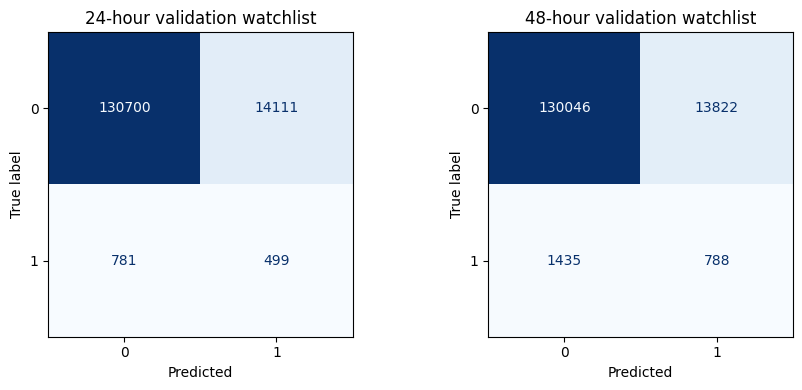

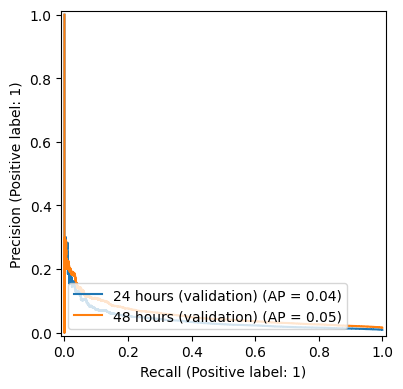

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, hours, actual, flags in [
    (axes[0], 24, y_24h.loc[val], val_flags_24h),
    (axes[1], 48, y_48h.loc[val], val_flags_48h),
]:
    matrix = confusion_matrix(actual, flags, labels=[0, 1])
    ConfusionMatrixDisplay(matrix).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{hours}-hour validation watchlist")
    ax.set_xlabel("Predicted")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
PrecisionRecallDisplay.from_predictions(y_24h.loc[val], val_risk_24h, name="24 hours (validation)", ax=ax)
PrecisionRecallDisplay.from_predictions(y_48h.loc[val], val_risk_48h, name="48 hours (validation)", ax=ax)
plt.tight_layout()
plt.show()

## Compare ROC Curves for Both Models on the Validation Set

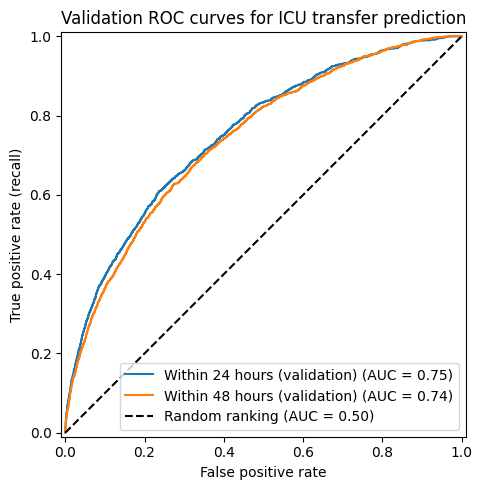

In [40]:
from sklearn.metrics import RocCurveDisplay


fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_24h.loc[val], val_risk_24h, name="Within 24 hours (validation)", ax=ax
)
RocCurveDisplay.from_predictions(
    y_48h.loc[val], val_risk_48h, name="Within 48 hours (validation)", ax=ax
)


ax.plot([0, 1], [0, 1], "k--", label="Random ranking (AUC = 0.50)")
ax.set_title("Validation ROC curves for ICU transfer prediction")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Compare the Top 10 Features in the 24-Hour and 48-Hour Models

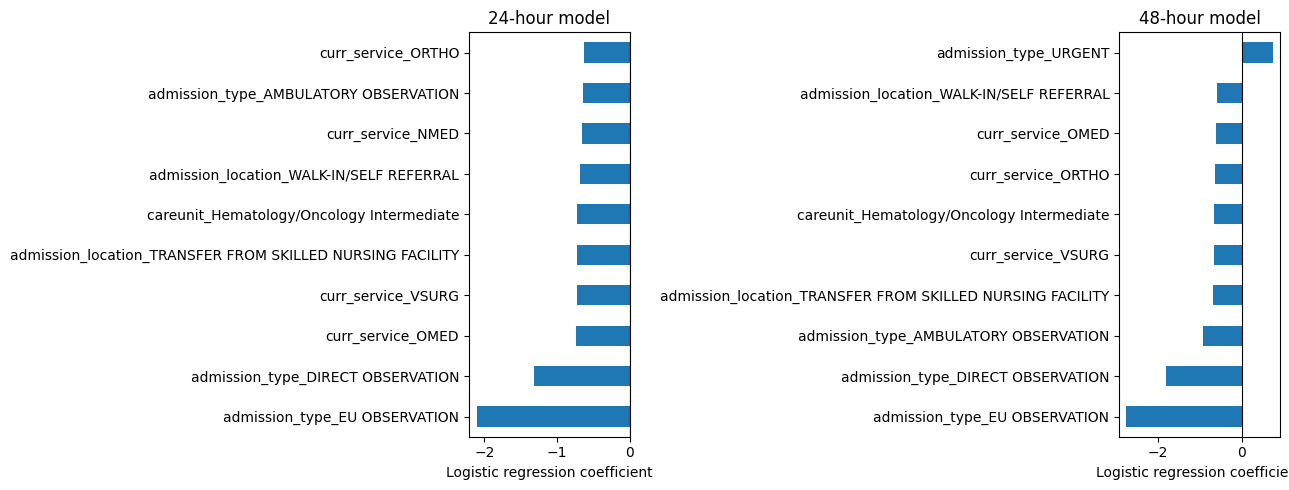

In [49]:

feature_names = prep.get_feature_names_out()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model, title, ax in zip(
    [model_24h, model_48h], ["24-hour model", "48-hour model"], axes
):

    coef = pd.Series(model.coef_[0], index=feature_names)
    coef.index = coef.index.str.split("__", n=1).str[-1]
    top_names = coef.abs().nlargest(10).index
    top = coef.loc[top_names].sort_values()
    top.plot.barh(ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Logistic regression coefficient")

plt.tight_layout()
plt.show()

## Display the 10 Highest-Risk Validation Snapshots

In [50]:
out = df.loc[val, ["subject_id", "hadm_id", "snapshot_time"]].copy()
out["risk_24h"] = val_risk_24h
out["risk_48h"] = val_risk_48h
out["actual_24h"] = y_24h.loc[val]
out["actual_48h"] = y_48h.loc[val]
out.sort_values("risk_24h", ascending=False).head(10).round(3)

,subject_id,hadm_id,snapshot_time,risk_24h,risk_48h,actual_24h,actual_48h
433354,15978157,25888959,2185-02-02 08:00:00,0.908,0.862,0,0
363930,15013421,22944754,2175-06-03 08:00:00,0.853,0.878,0,0
641496,18849858,28433475,2188-01-30 08:00:00,0.851,0.799,0,0
575999,17955561,21265229,2131-04-07 08:00:00,0.836,0.851,0,0
457676,16312465,29818483,2176-05-11 08:00:00,0.830,0.807,0,0
553341,17653383,26880737,2117-09-03 08:00:00,0.808,0.793,1,1
320708,14380537,20657041,2126-09-15 08:00:00,0.770,0.724,1,1
433352,15978157,25888959,2185-01-31 08:00:00,0.736,0.729,0,0
21118,10321676,27144203,2169-10-26 08:00:00,0.688,0.628,0,0
457675,16312465,29818483,2176-05-10 08:00:00,0.672,0.689,0,0
